# Data Understanding

This notebook focuses on understanding the structure, content, and basic characteristics of the California Housing Prices dataset before data preparation and exploratory data analysis (EDA).

## Objectives

* Load the dataset
* Inspect the first and last rows
* Examine the dataset structure and data types
* Review basic statistical information
* Identify missing values
* Check for duplicate records
* Develop an initial understanding of the features and the target variable (`median_house_value`)

In [1]:
import pandas as pd

### 1. Load Dataset

In [2]:
df = pd.read_csv("../data/housing.csv")

### 2. Initial Inspection

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


### 3. Data Types and Structure

In [5]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.info()

Rows: 20640, Columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


#### Initial Observations
The dataset contains 20,640 records and 10 columns.
It includes numerical and categorical features, with `median_house_value`
as the target variable.
Most features are numerical, while `ocean_proximity` is categorical.

### 4. Statistical Summary

In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Numerical features vary widely in scale — for example, `total_rooms` and `population` span much larger ranges than `median_income`. This will need to be addressed with scaling during data preparation.

### 5. Missing Values

In [7]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent.round(2)
})
missing_df[missing_df["missing_count"] > 0]

,missing_count,missing_percent
total_bedrooms,207,1.0


The `total_bedrooms` column contains missing values, at a small percentage of total records.

### 6. Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(0)

### 7. Categorical Feature Distribution

In [9]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

### 8. Unique Value Counts

In [10]:
df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64

### 9. Correlation with Target

In [11]:
correlation = df.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)
correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

`median_income` shows the strongest positive correlation with `median_house_value`, making it likely to be one of the most important predictive features.

### 10. Histograms of Numerical Features

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

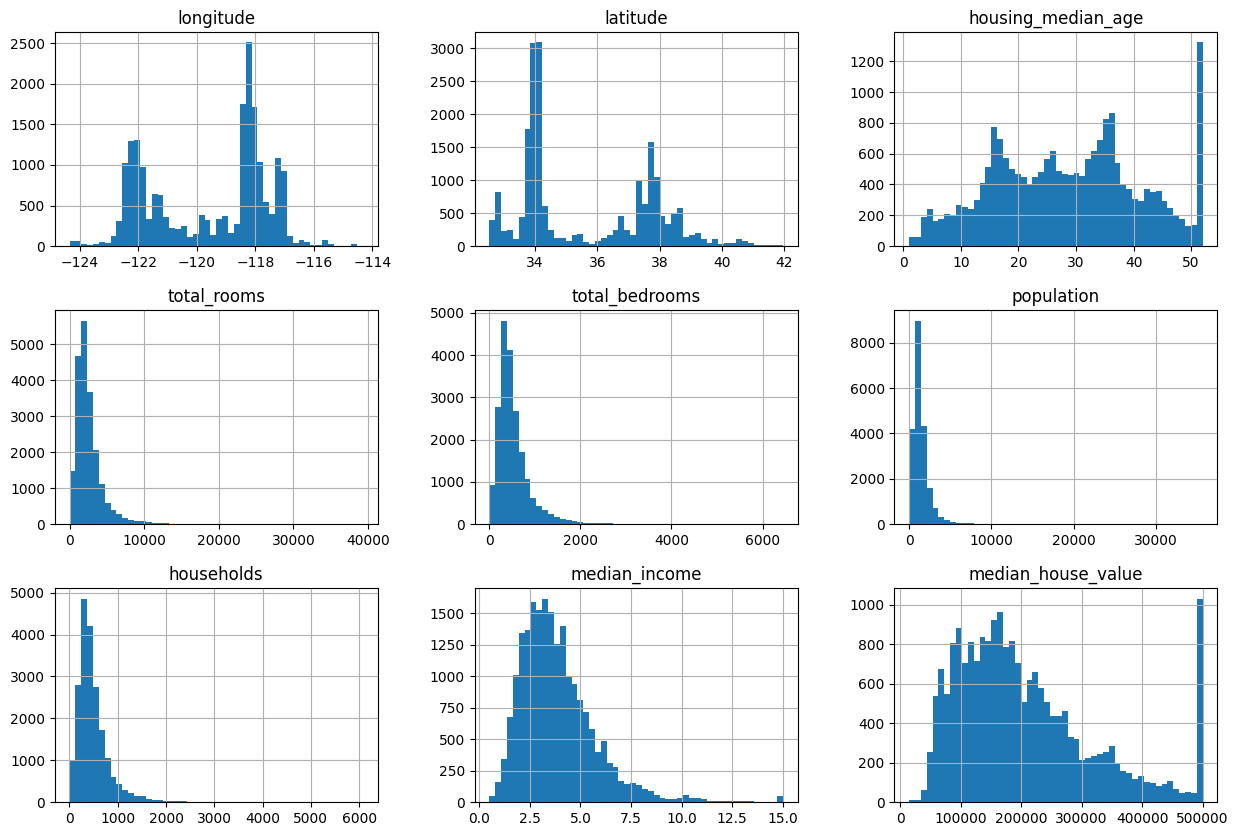

In [13]:
%matplotlib inline
df.hist(bins=50, figsize=(15, 10))

#### Observations from Histograms

* Numerical features have very different scales, confirming the earlier 
  observation from `describe()` — this will need to be addressed with 
  feature scaling.
* Several distributions are right-skewed (a longer tail on the high-value 
  side than the low-value side). Skewed distributions can make it harder 
  for some algorithms to detect patterns, so a transformation (e.g. log 
  transform) may be considered later.
* `median_income` does not appear to be in raw US dollars — its values 
  seem to be scaled and capped (roughly between 0.5 and 15). This suggests 
  the feature was preprocessed before being included in the dataset.
* `housing_median_age` and `median_house_value` both show a spike at their 
  maximum value, suggesting they were capped during data collection or 
  preprocessing. The capping in `median_house_value` is particularly 
  important since it's the target variable — a model trained on this data 
  could learn to never predict values beyond the cap. This will need to be 
  addressed in data preparation, either by removing the capped records or, 
  ideally, by obtaining true values for them.

## Data Understanding Summary

The dataset contains housing and demographic information for California housing districts. The target variable is `median_house_value`.

The dataset contains both numerical and categorical features. The `ocean_proximity` feature is categorical, while the remaining features are numerical, and their scales vary considerably.

Missing values were identified in `total_bedrooms`. No duplicate records were identified.

`median_income` shows the strongest correlation with the target variable among numerical features.

Histogram analysis revealed additional characteristics of the data: several numerical features are right-skewed, `median_income` appears to be a preprocessed feature (scaled and capped rather than in raw dollars), and both `housing_median_age` and `median_house_value` show signs of capping at their maximum values. The capping in `median_house_value` is particularly important to address in data preparation, since it is the target variable and could bias the model's predictions.

The dataset requires further data preparation — including handling missing values, scaling and transforming skewed numerical features, addressing the capped target variable, and encoding the categorical feature — before it can be used for machine learning.